# History matching a waterflood with the ensemble smoother

This notebook is a stripped-down version of the `waterflood` example

In [1]:
import iterative_ensemble_smoother as ies
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm
from minires import Grid2D, ResSim
from minires.geostat import gaussian_fields

## The reservoir

A 1000 x 1000 x 20 m box with 32 x 32 cells, holding oil that is
five times more viscous than the water. One injector at the centre pumps
1000 m³/day; four producers towards the corners are held at 250 bar, so their rates,
and when the injected water reaches them, follow from how the permeability steers
the flood. 

The time horizon is 40 report steps of 60 days. We only have observations for the
first 16 steps (960 days). The remaining 24 steps are the forecast.

In [2]:
from itertools import starmap

nx = ny = 32  # cells
lx = 1000.0  # extent [m]
dz = 20.0  # thickness [m]
porosity = 0.2

fluid = {"vw": 1.0, "vo": 5.0, "swc": 0.2, "sor": 0.2, "nw": 2, "no": 2}
injector = {"INJ": (0.5 * lx, 0.5 * lx)}
producers = {
    "PROD1": (0.15 * lx, 0.15 * lx),
    "PROD2": (0.85 * lx, 0.15 * lx),
    "PROD3": (0.15 * lx, 0.85 * lx),
    "PROD4": (0.85 * lx, 0.85 * lx),
}

dt = 60.0  # [days]
nsteps = 40
nsteps_history = 16
obs_steps = np.arange(4, nsteps_history + 1, 4)
days = dt * np.arange(1, nsteps + 1)

grid = Grid2D(Lx=lx, Ly=lx, Nx=nx, Ny=ny)

## The forward model

Given a permeability field, `simulate` returns the water cut (the fraction of the produced fluid that
is water) of each producer at the end of every report step. It is zero until the injected water breaks
through.

The constant `0.008527` is the unit conversion Darcy's law needs when permeability is
in milliDarcy, pressure in bar, viscosity in centipoise and time in days.

In [3]:
def simulate(log_permeability):
    """Water cut of each producer at the end of each report step, shape (nsteps, 4)."""
    wells = {
        name: {"xy": list(xy), "rate": 1000.0 / dz, "rw": 0.15}
        for name, xy in injector.items()
    } | {
        name: {"xy": list(xy), "bhp": 250.0, "rw": 0.15}
        for name, xy in producers.items()
    }
    model = ResSim(
        Lx=lx,
        Ly=lx,
        Nx=nx,
        Ny=ny,
        cdarcy=0.008527,
        K=np.exp(log_permeability).reshape(nx, ny),
        por=np.full((nx, ny), porosity),
        ct=1e-5,
        fluid=fluid,
        wells=wells,
    )
    saturation, _ = model.sim(
        dt,
        nsteps,
        S0=np.full(model.Nxy, fluid["swc"]),
        P0=np.full(model.Nxy, 300.0),
        pbar=False,
    )
    cells = list(starmap(model.xy2ind, producers.values()))
    return np.array([model.fluid.fractional_flow(s)[cells] for s in saturation[1:]])

## The prior

What we do not know is the permeability of the cells. Our prior belief is
that it is log-normal around 200 mD with a Gaussian variogram of 300 m range. We use the logarithm
of permeability throughout, since that is what
is approximately Gaussian, and the ensemble smoother expects that.

In [4]:
perm_mean = 200.0  # [mD]
perm_std = 0.8  # standard deviation of log(K)
corr_length = 300.0  # [m]


def sample_log_permeability(n, rng):
    """`n` realizations of the prior, shape (n, nx * ny)."""
    fields = gaussian_fields(grid.mesh, n, corr_length, rng)
    return np.log(perm_mean) + perm_std * fields

## The truth

In a real history match the truth is unknown. Here we make one up by drawing a
realization from the prior, so that we can compare the update against a synthetic truth.

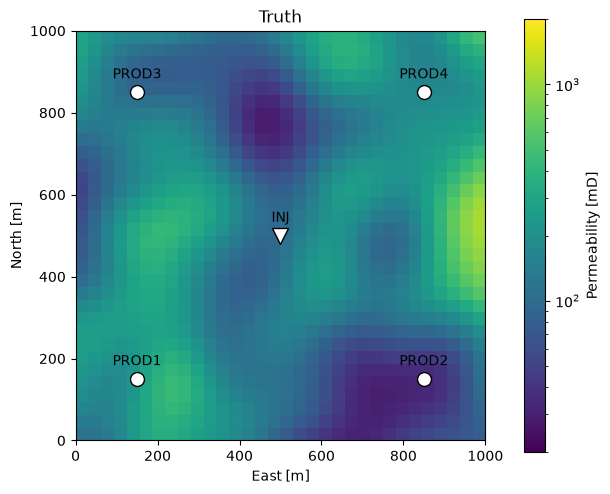

In [5]:
rng = np.random.default_rng(20220906)
truth = sample_log_permeability(1, rng)[0]


def plot_wells(ax):
    for name, (east, north) in injector.items():
        ax.plot(east, north, "v", color="white", mec="black", ms=12)
        ax.annotate(
            name, (east, north), (0, 10), textcoords="offset points", ha="center"
        )
    for name, (east, north) in producers.items():
        ax.plot(east, north, "o", color="white", mec="black", ms=10)
        ax.annotate(
            name, (east, north), (0, 10), textcoords="offset points", ha="center"
        )


def plot_permeability(ax, log_permeability, title):
    image = ax.imshow(
        np.exp(log_permeability).reshape(nx, ny).T,
        origin="lower",
        extent=(0, lx, 0, lx),
        norm=LogNorm(vmin=20, vmax=2000),
        cmap="viridis",
    )
    plot_wells(ax)
    ax.set(title=title, xlabel="East [m]", ylabel="North [m]")
    return image


fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
fig.colorbar(plot_permeability(ax, truth, "Truth"), label="Permeability [mD]")
plt.show()

## The observations

Running the truth through the forward model gives us the water cut the wells would
have reported. Measurements are never exact, so we add noise, 5 % of the value and at
least 0.02, and record that noise level as the observation error.

In [6]:
truth_water_cut = simulate(truth)

obs_true = truth_water_cut[obs_steps - 1]
obs_std = np.maximum(0.05 * obs_true, 0.02)
obs_values = np.clip(obs_true + rng.normal(scale=obs_std), 0, 1)

print("Water cut observations (rows: report steps, columns: producers)")
print(np.round(obs_values, 3))

Water cut observations (rows: report steps, columns: producers)
[[0.    0.    0.005 0.   ]
 [0.    0.032 0.021 0.   ]
 [0.318 0.005 0.076 0.419]
 [0.499 0.021 0.364 0.549]]


## Simulate the prior ensemble

We draw an ensemble of 50 realizations from the prior and run the forward model on
each which gives us the prior.

The convention of `iterative_ensemble_smoother` is one *column* per realization:
`X` holds the parameters, one row per cell, and `Y` the simulated counterparts of the
observations, one row per observation.

In [7]:
ensemble_size = 50

X_prior = sample_log_permeability(ensemble_size, rng).T
water_cut_prior = np.array([simulate(x) for x in X_prior.T])
Y_prior = water_cut_prior[:, obs_steps - 1].reshape(ensemble_size, -1).T

print(f"Parameters X: {X_prior.shape}, responses Y: {Y_prior.shape}")

Parameters X: (1024, 50), responses Y: (16, 50)


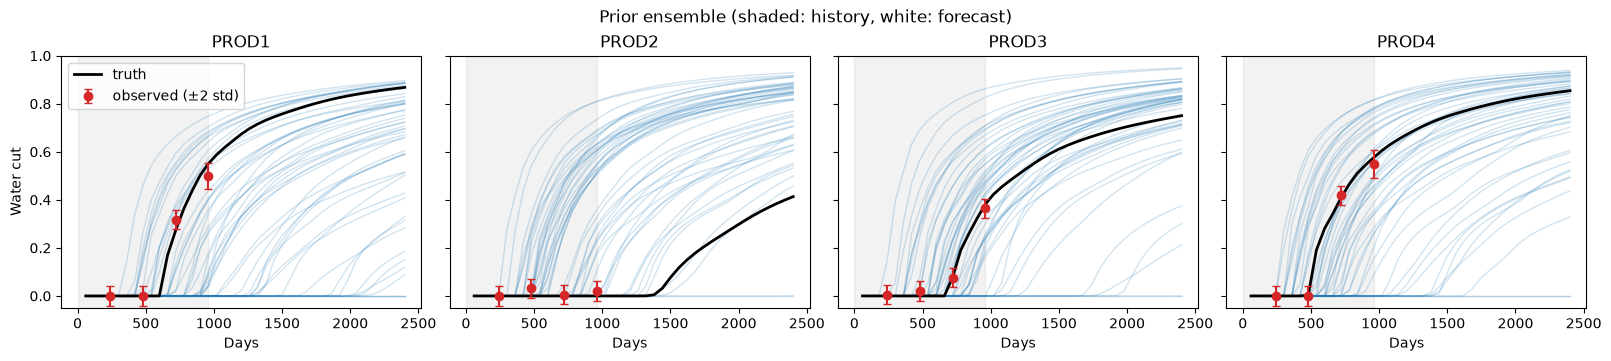

In [8]:
def plot_water_cut(water_cut, title):
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True, layout="constrained")
    for i, (ax, name) in enumerate(zip(axes, producers, strict=True)):
        ax.plot(days, water_cut[:, :, i].T, color="C0", alpha=0.2, lw=1)
        ax.plot(days, truth_water_cut[:, i], "k", lw=2, label="truth")
        ax.errorbar(
            days[obs_steps - 1],
            obs_values[:, i],
            2 * obs_std[:, i],
            fmt="o",
            color="C3",
            capsize=3,
            label="observed (±2 std)",
        )
        ax.axvspan(0, dt * nsteps_history, color="gray", alpha=0.1)
        ax.set(title=name, xlabel="Days", ylim=(-0.05, 1))
    axes[0].set_ylabel("Water cut")
    axes[0].legend(loc="upper left")
    fig.suptitle(f"{title} (shaded: history, white: forecast)")
    plt.show()


plot_water_cut(water_cut_prior, "Prior ensemble")

## The update

The ensemble smoother updates every parameter on the simulated
responses. Where the ensemble shows that a cell's permeability covaries with a
producer's water cut, that cell is nudged in the direction that brings the water cut
towards what was observed.

In [9]:
smoother = ies.ESMDA(
    covariance=obs_std.ravel() ** 2,
    observations=obs_values.ravel(),
    alpha=1,
    seed=42,
)
smoother.prepare_assimilation(Y=Y_prior)
X_posterior = smoother.assimilate_batch(X=X_prior)

water_cut_posterior = np.array([simulate(x) for x in X_posterior.T])
Y_posterior = water_cut_posterior[:, obs_steps - 1].reshape(ensemble_size, -1).T

## Before and after

The permeability maps below show the truth against the ensemble average before and
after the update.

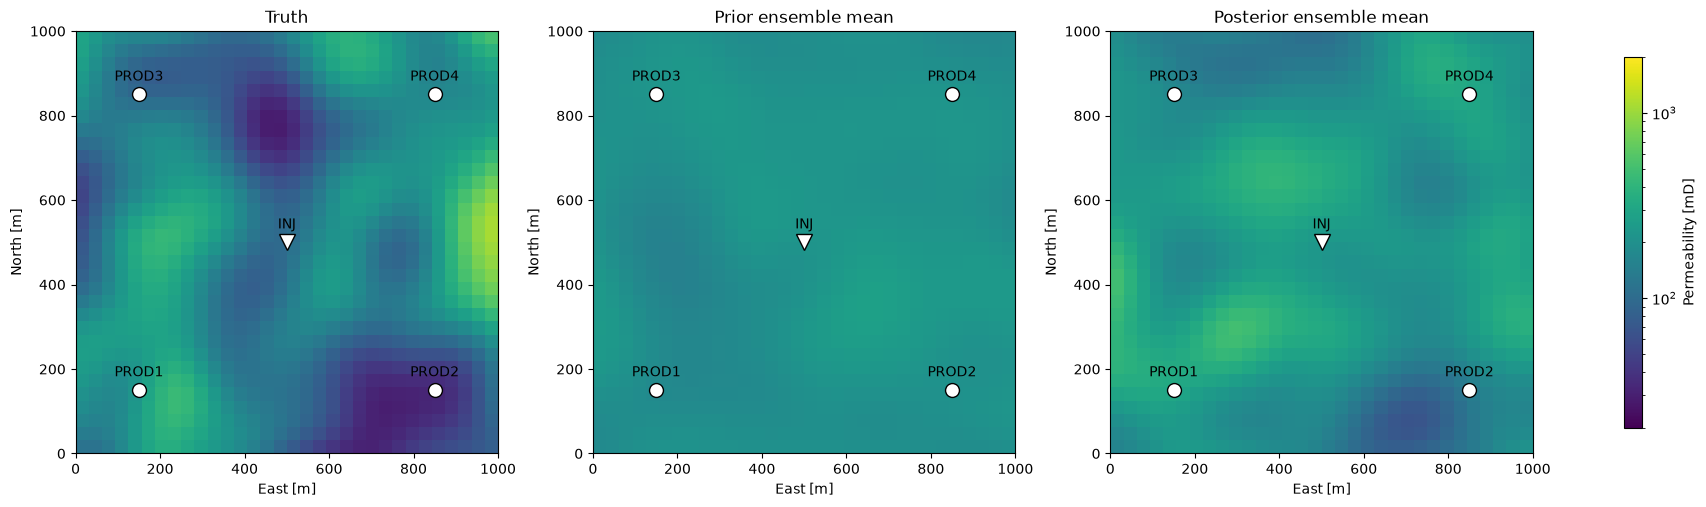

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), layout="constrained")
plot_permeability(axes[0], truth, "Truth")
plot_permeability(axes[1], X_prior.mean(axis=1), "Prior ensemble mean")
image = plot_permeability(axes[2], X_posterior.mean(axis=1), "Posterior ensemble mean")
fig.colorbar(image, ax=axes, label="Permeability [mD]", shrink=0.8)
plt.show()

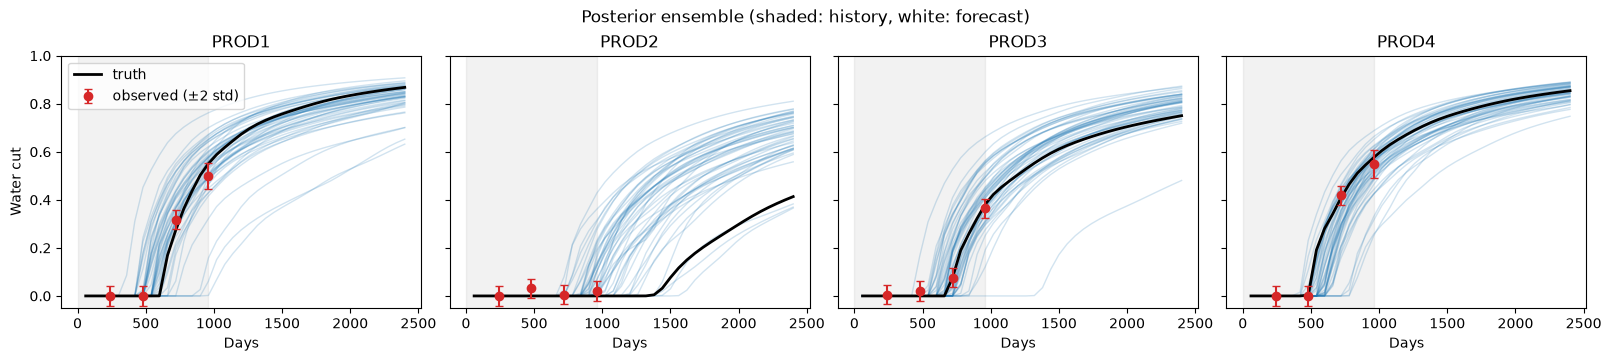

In [11]:
plot_water_cut(water_cut_posterior, "Posterior ensemble")

In [12]:
def rmse_log_permeability(X):
    return np.sqrt(((X.mean(axis=1) - truth) ** 2).mean())


def misfit(Y):
    normalized = (Y - obs_values.ravel()[:, None]) / obs_std.ravel()[:, None]
    return (normalized**2).mean()


def forecast_error(water_cut):
    forecast = slice(nsteps_history, nsteps)
    return np.sqrt(
        ((water_cut.mean(axis=0)[forecast] - truth_water_cut[forecast]) ** 2).mean()
    )


header = ("", "misfit", "RMSE log K", "spread log K", "RMSE forecast")
print("{:10} {:>8} {:>11} {:>13} {:>14}".format(*header))
for name, X, Y, wct in [
    ("prior", X_prior, Y_prior, water_cut_prior),
    ("posterior", X_posterior, Y_posterior, water_cut_posterior),
]:
    print(
        f"{name:10} {misfit(Y):8.1f} {rmse_log_permeability(X):11.3f} "
        f"{X.std(axis=1).mean():13.3f} {forecast_error(wct):14.3f}"
    )

             misfit  RMSE log K  spread log K  RMSE forecast
prior         132.2       0.803         0.782          0.276
posterior      21.4       0.751         0.641          0.152
